In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from src.features import load_audio, extract_chroma, extract_mfcc

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [ ]:
AUDIO_EXTENSIONS = ['.wav', '.mp3', '.flac', '.ogg']
SR = 22050
TARGET_DURATION = 2.0

audio_dirs = [
    Path('../data/Audio_Files'),
    Path('../data/shords_dataset')
]

audio_data = []

for data_dir in audio_dirs:
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        for f in label_dir.iterdir():
            if f.suffix.lower() not in AUDIO_EXTENSIONS:
                continue
            y, sr = load_audio(str(f), sr=SR, target_duration=TARGET_DURATION)
            audio_data.append((y, sr, label, data_dir.name))

print(f"Total samples loaded: {len(audio_data)}")
labels_all = [d[2] for d in audio_data]
sources_all = [d[3] for d in audio_data]
unique, counts = np.unique(labels_all, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {u}: {c}")

src_labels = pd.DataFrame({'label': labels_all, 'source': sources_all})
print("\nPer-source breakdown:")
print(src_labels.groupby(['source', 'label']).size().unstack(fill_value=0))

Total samples loaded: 1361
  Major: 752
  Minor: 609

Per-source breakdown:
label           Major  Minor
source                      
Audio_Files       502    357
shords_dataset    250    252


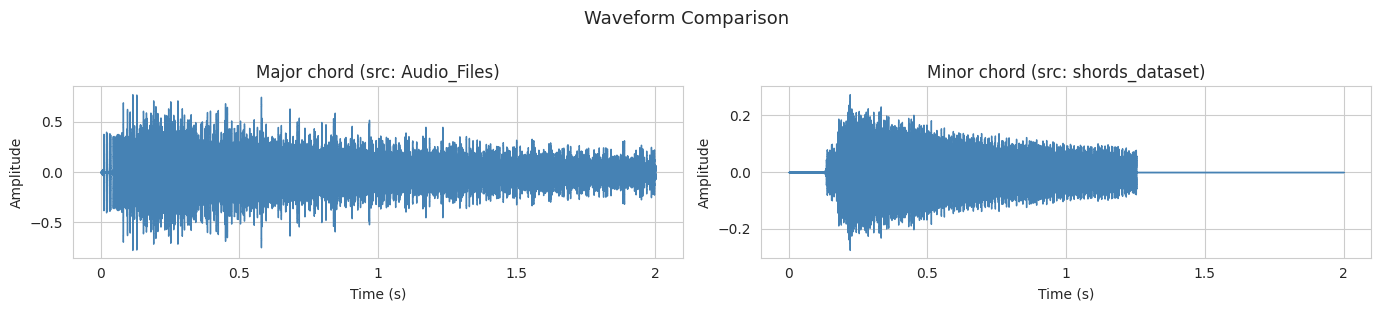

In [ ]:
rng = np.random.RandomState(42)

major_indices = [i for i, d in enumerate(audio_data) if d[2] == 'Major']
minor_indices = [i for i, d in enumerate(audio_data) if d[2] == 'Minor']

idx_maj = rng.choice(major_indices)
idx_min = rng.choice(minor_indices)

samples = [
    ('Major chord', audio_data[idx_maj]),
    ('Minor chord', audio_data[idx_min])
]

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
for ax, (title, (y, sr, label, src)) in zip(axes, samples):
    librosa.display.waveshow(y, sr=sr, ax=ax, color='steelblue')
    ax.set_title(f'{title} (src: {src})')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')
plt.suptitle('Waveform Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

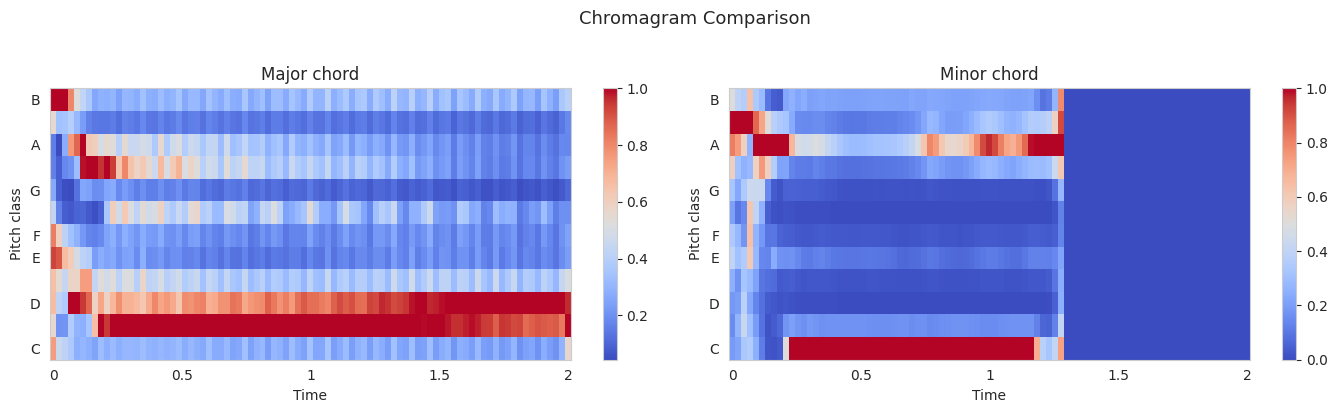

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (title, (y, sr, label, src)) in zip(axes, samples):
    chroma = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=512)
    img = librosa.display.specshow(chroma, y_axis='chroma', x_axis='time',
                                   sr=sr, hop_length=512, ax=ax, cmap='coolwarm')
    ax.set_title(f'{title}')
    fig.colorbar(img, ax=ax, format='%.1f')
plt.suptitle('Chromagram Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

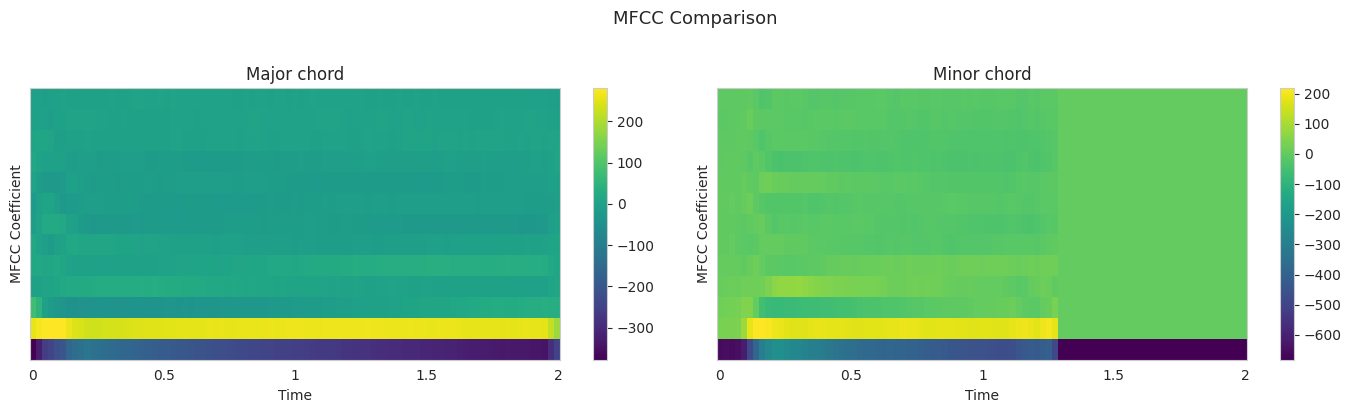

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (title, (y, sr, label, src)) in zip(axes, samples):
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, hop_length=512)
    img = librosa.display.specshow(mfccs, x_axis='time', sr=sr,
                                   hop_length=512, ax=ax, cmap='viridis')
    ax.set_ylabel('MFCC Coefficient')
    ax.set_title(f'{title}')
    fig.colorbar(img, ax=ax)
plt.suptitle('MFCC Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

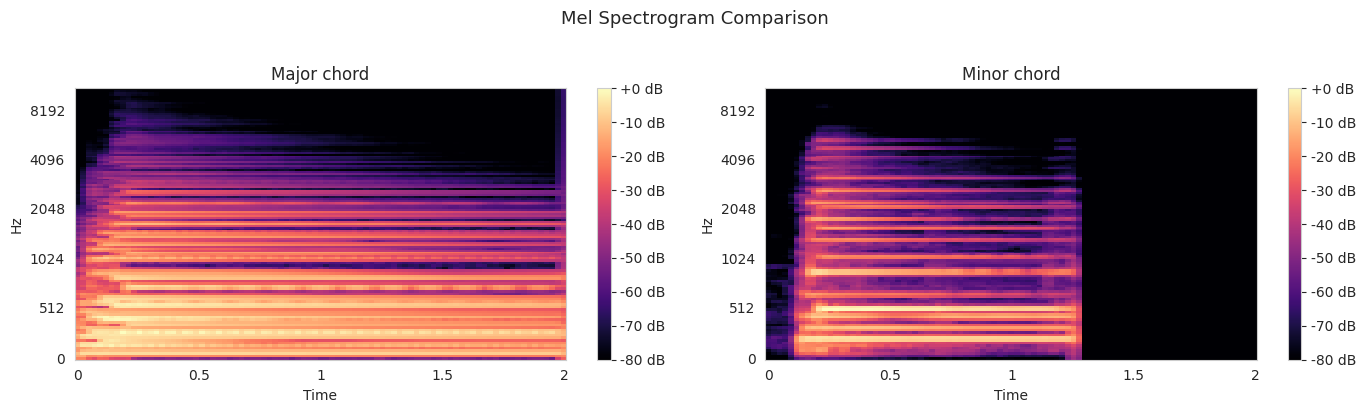

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (title, (y, sr, label, src)) in zip(axes, samples):
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, x_axis='time', y_axis='mel',
                                   sr=sr, hop_length=512, ax=ax, cmap='magma')
    ax.set_title(f'{title}')
    fig.colorbar(img, ax=ax, format='%+2.0f dB')
plt.suptitle('Mel Spectrogram Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
N_MELS_FEAT = 20

all_features = []
all_labels = []

for y, sr, label, src in audio_data:
    chroma = extract_chroma(y, sr)
    mfcc = extract_mfcc(y, sr)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS_FEAT, hop_length=512)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_mean = np.mean(mel_db, axis=1)

    feat = np.concatenate([chroma, mfcc, mel_mean])
    all_features.append(feat)
    all_labels.append(label)

features = np.array(all_features)
labels = np.array(all_labels)

chroma_names = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
mfcc_names = [f'MFCC_{i}' for i in range(13)]
mel_names = [f'Mel_{i}' for i in range(N_MELS_FEAT)]
feature_names = chroma_names + mfcc_names + mel_names

df = pd.DataFrame(features, columns=feature_names)
df['label'] = labels

print(f"Feature matrix shape: {features.shape}")
df.describe().round(2)

Feature matrix shape: (1361, 45)


,C,C#,D,D#,E,F,F#,G,G#,A,...,Mel_10,Mel_11,Mel_12,Mel_13,Mel_14,Mel_15,Mel_16,Mel_17,Mel_18,Mel_19
count,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,...,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00,1361.00
mean,0.32,0.31,0.28,0.31,0.32,0.29,0.29,0.28,0.26,0.30,...,-46.06,-50.33,-55.28,-60.62,-63.70,-67.15,-69.83,-73.80,-75.67,-77.17
std,0.24,0.25,0.23,0.23,0.25,0.24,0.23,0.22,0.20,0.24,...,12.75,13.48,12.72,12.26,11.61,11.05,9.87,7.83,6.32,4.56
min,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,...,-72.00,-75.32,-77.74,-78.60,-79.00,-79.47,-79.97,-80.00,-80.00,-80.00
25%,0.15,0.13,0.12,0.13,0.13,0.11,0.11,0.11,0.12,0.12,...,-57.88,-63.37,-66.28,-69.22,-72.34,-73.99,-75.11,-77.65,-78.93,-79.43
50%,0.26,0.25,0.21,0.26,0.23,0.22,0.22,0.21,0.22,0.24,...,-44.83,-49.43,-55.06,-62.33,-64.73,-69.89,-72.51,-75.88,-77.46,-78.69
75%,0.44,0.42,0.38,0.45,0.44,0.36,0.40,0.39,0.35,0.39,...,-35.91,-40.18,-47.22,-57.80,-61.24,-66.71,-70.00,-74.35,-76.16,-77.53
max,1.00,1.00,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,-12.73,-13.16,-16.96,-16.73,-18.05,-22.77,-28.18,-37.94,-44.18,-53.30


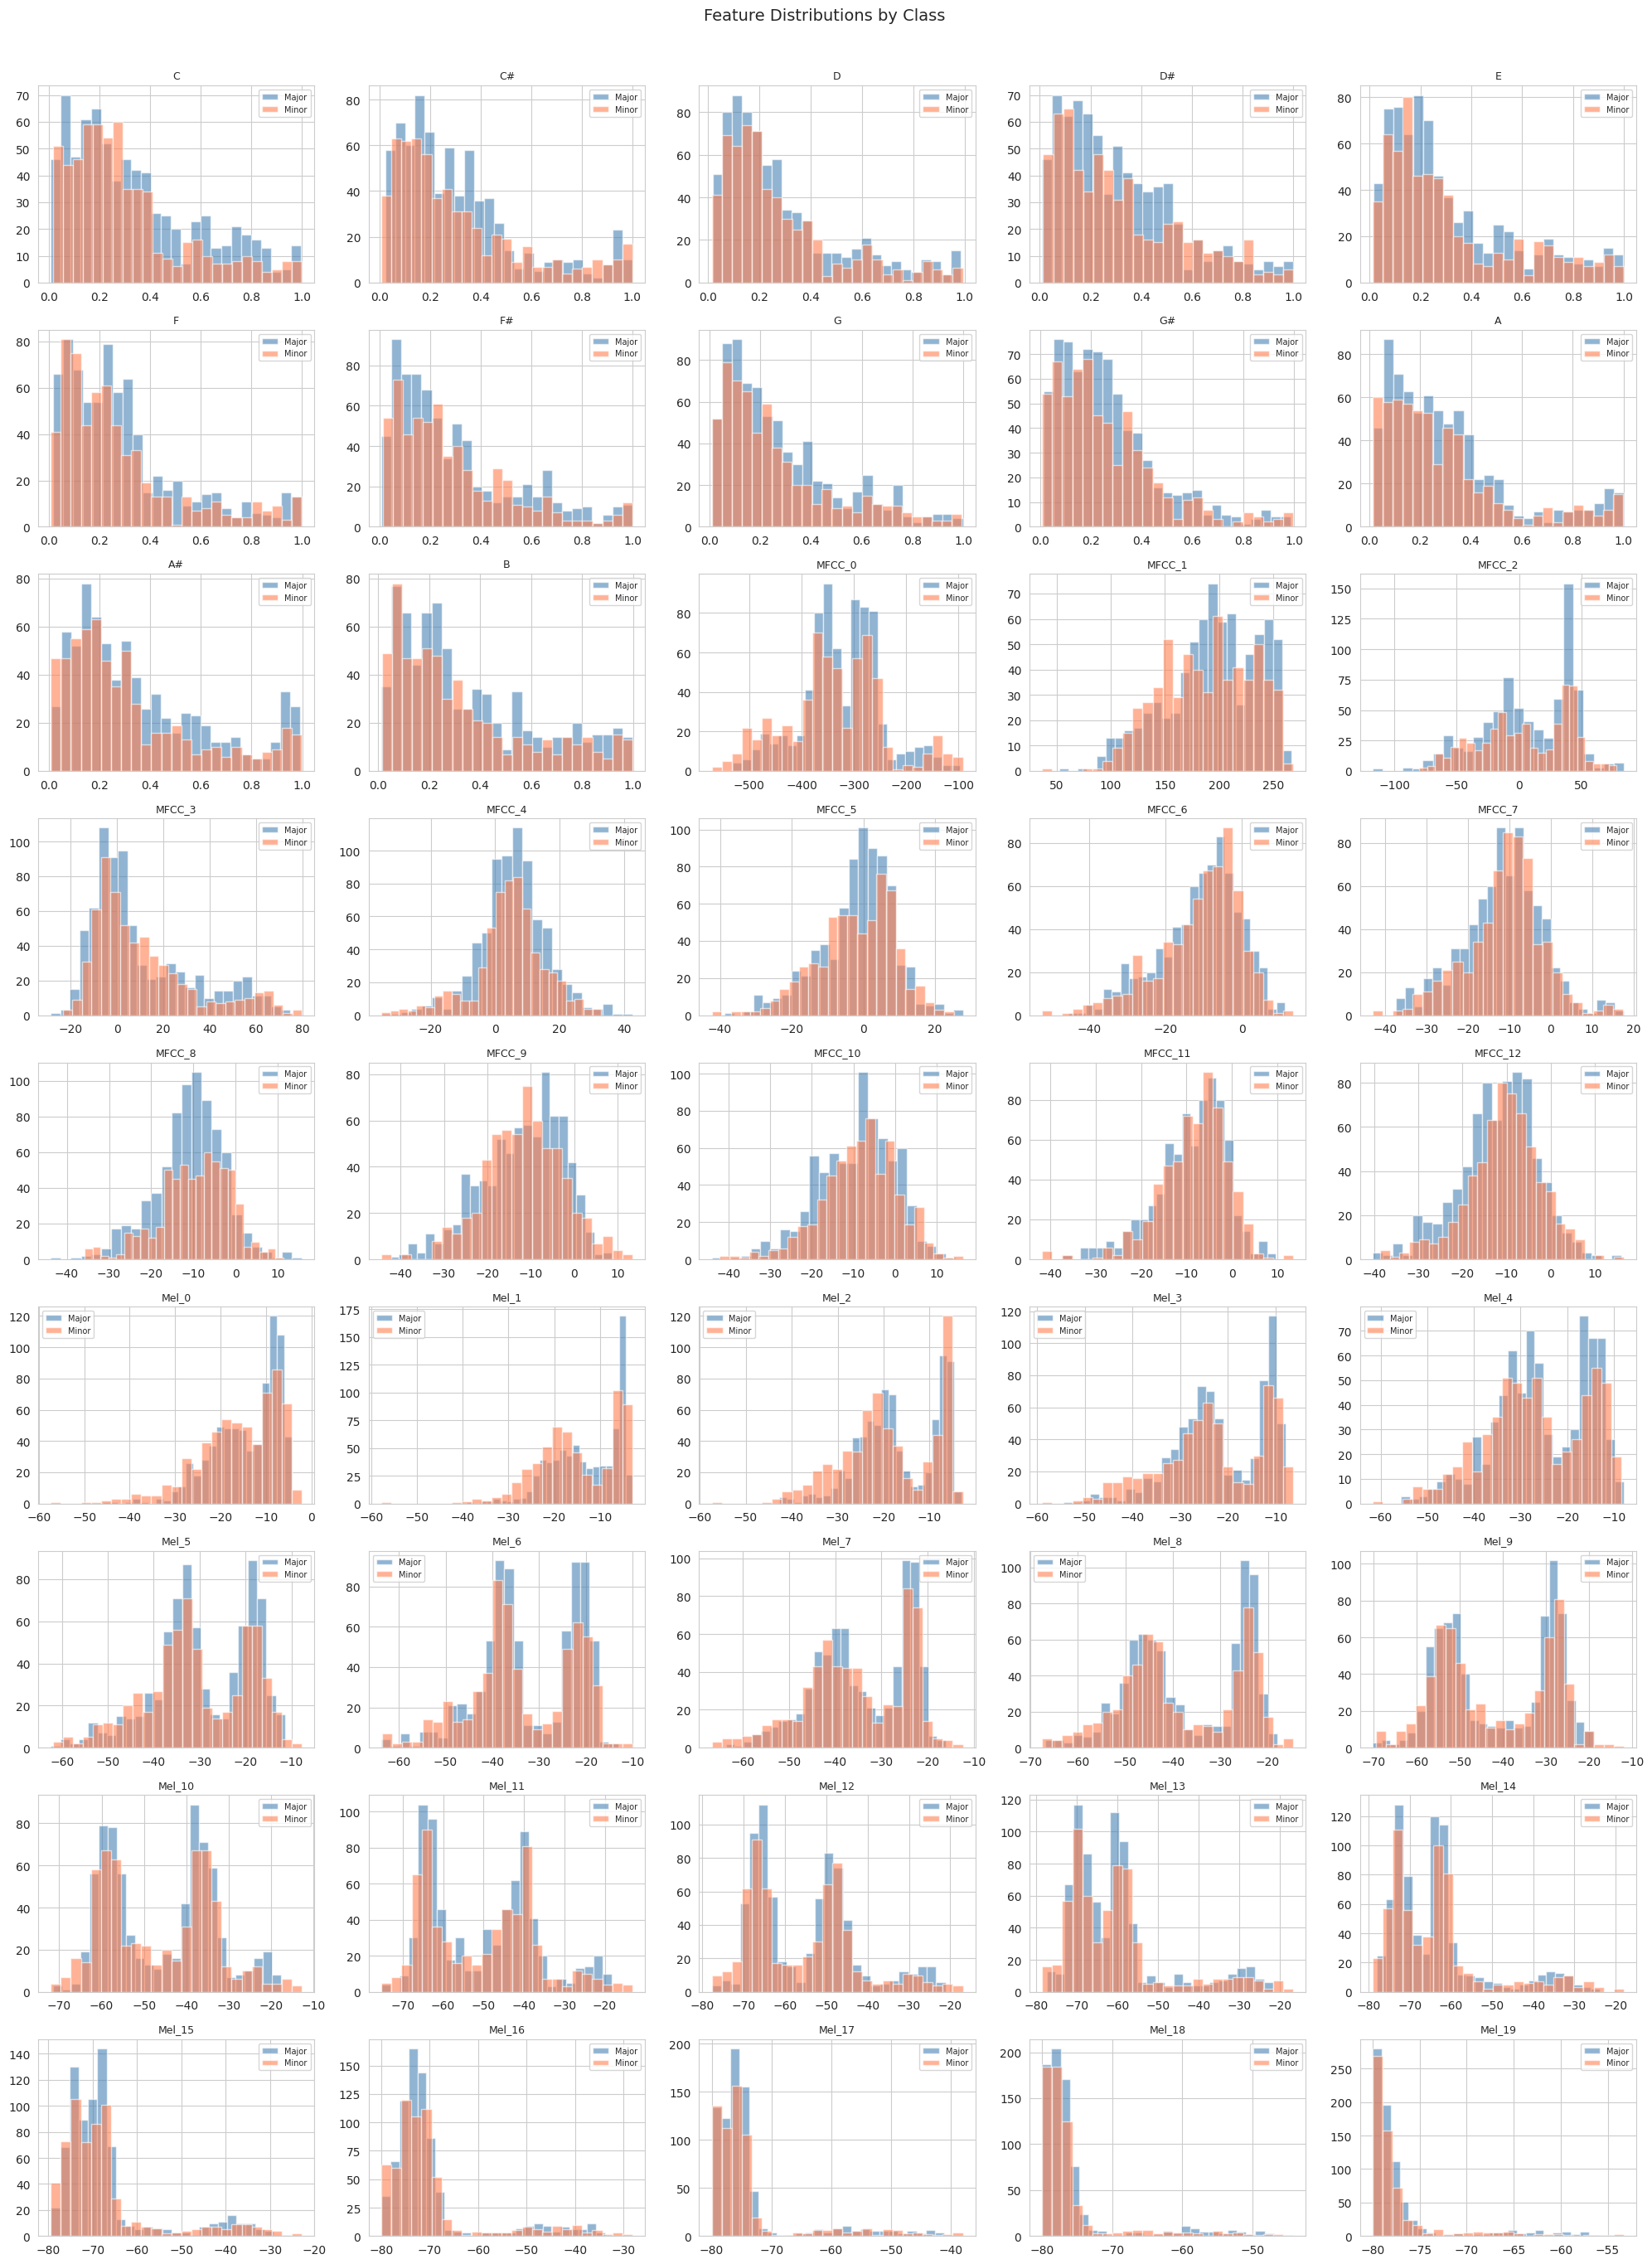

In [ ]:
n_features = len(feature_names)
n_cols = 5
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3 * n_rows))
axes = axes.flatten()

for i, col in enumerate(feature_names):
    ax = axes[i]
    df[df['label'] == 'Major'][col].hist(ax=ax, bins=25, alpha=0.6, color='steelblue', label='Major')
    df[df['label'] == 'Minor'][col].hist(ax=ax, bins=25, alpha=0.6, color='coral', label='Minor')
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions by Class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

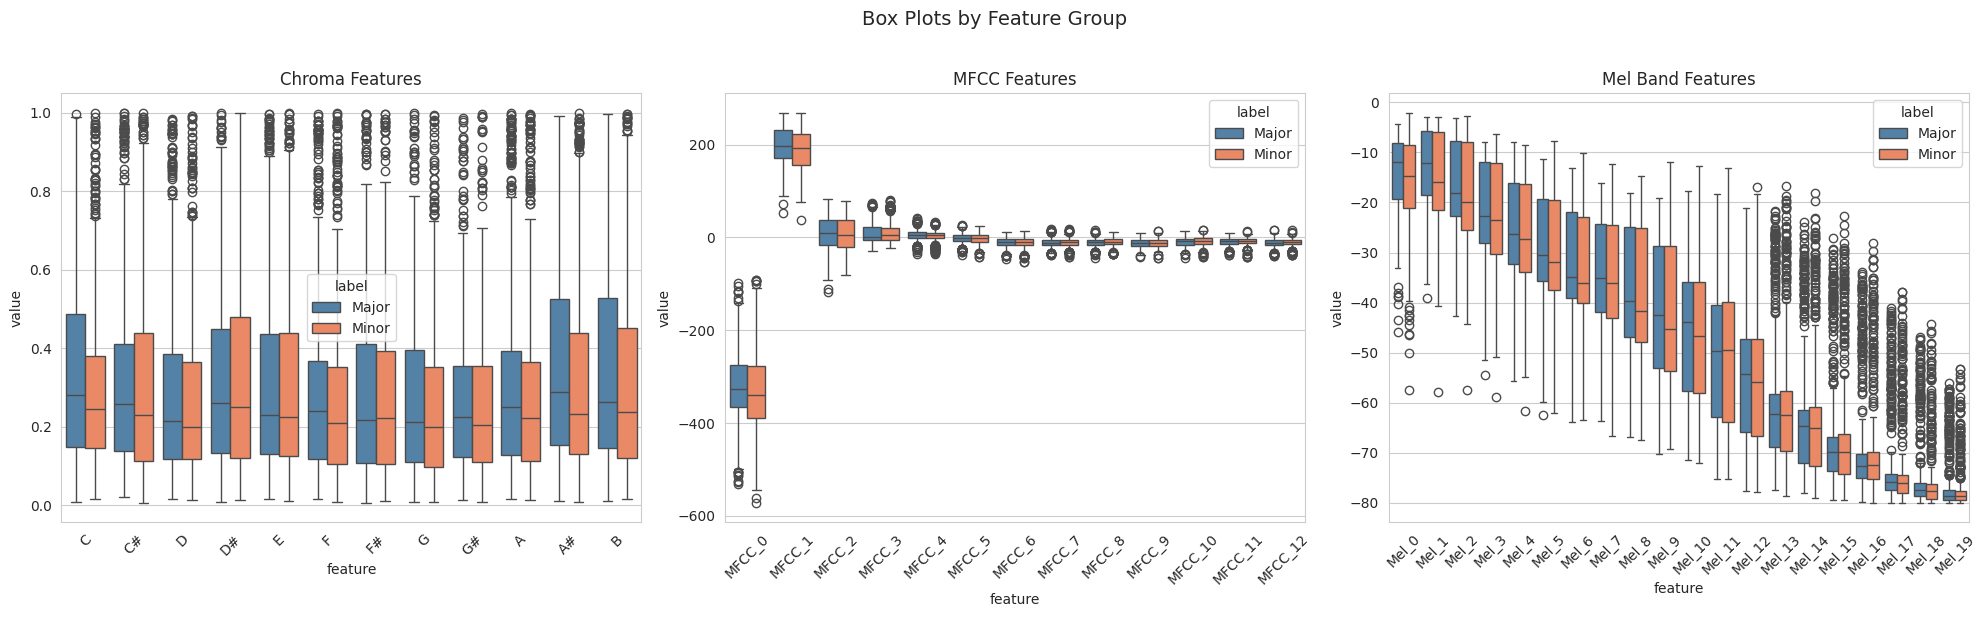

In [ ]:
palette = {'Major': 'steelblue', 'Minor': 'coral'}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

df_chroma = df[chroma_names + ['label']].melt(id_vars='label', var_name='feature', value_name='value')
sns.boxplot(data=df_chroma, x='feature', y='value', hue='label', palette=palette, ax=axes[0])
axes[0].set_title('Chroma Features')
axes[0].tick_params(axis='x', rotation=45)

df_mfcc = df[mfcc_names + ['label']].melt(id_vars='label', var_name='feature', value_name='value')
sns.boxplot(data=df_mfcc, x='feature', y='value', hue='label', palette=palette, ax=axes[1])
axes[1].set_title('MFCC Features')
axes[1].tick_params(axis='x', rotation=45)

df_mel = df[mel_names + ['label']].melt(id_vars='label', var_name='feature', value_name='value')
sns.boxplot(data=df_mel, x='feature', y='value', hue='label', palette=palette, ax=axes[2])
axes[2].set_title('Mel Band Features')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Box Plots by Feature Group', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

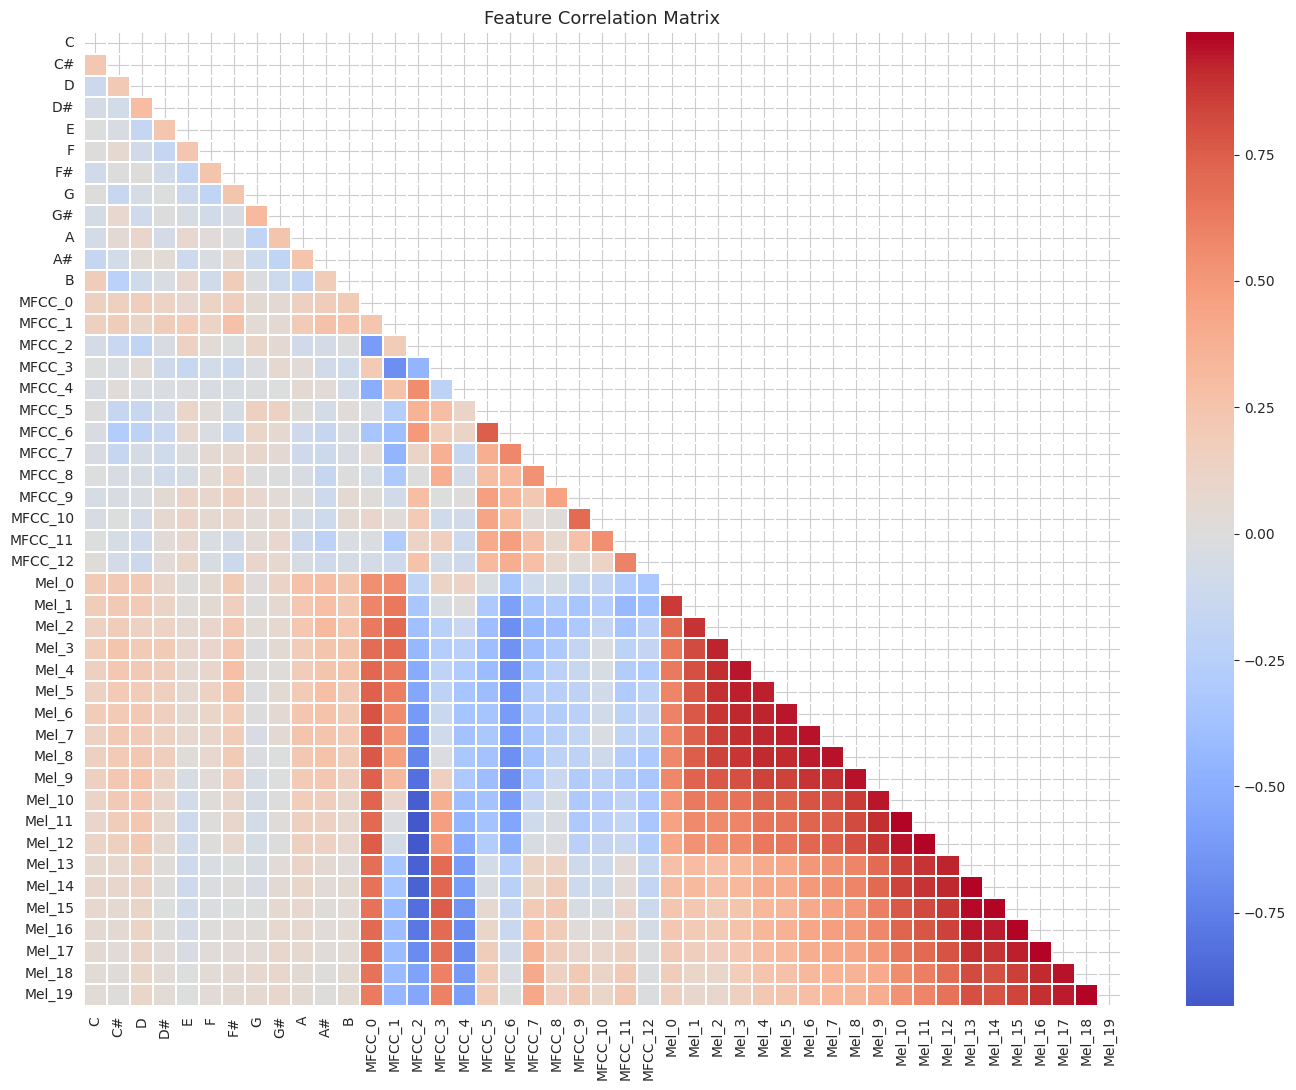

In [ ]:
fig, ax = plt.subplots(figsize=(14, 11))
corr = df[feature_names].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False,
            xticklabels=feature_names, yticklabels=feature_names, ax=ax,
            linewidths=0.3)
ax.set_title('Feature Correlation Matrix', fontsize=13)
plt.tight_layout()
plt.show()

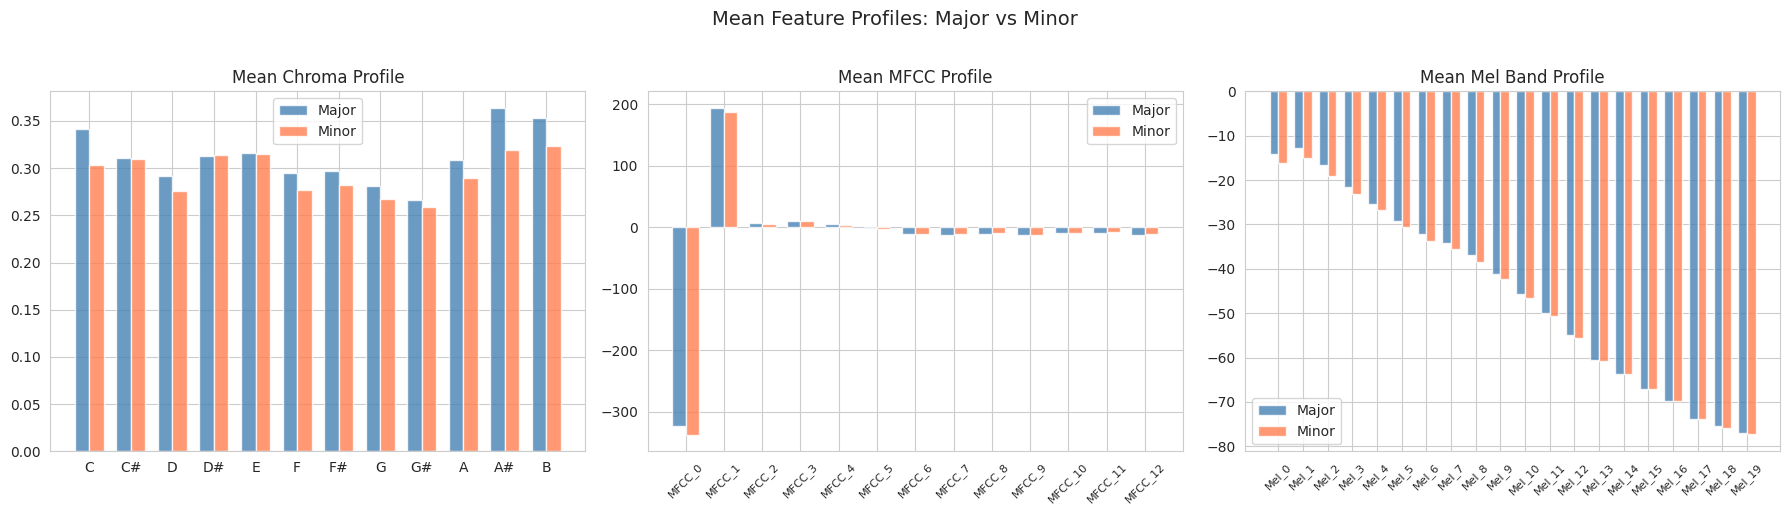

In [ ]:
major_mean = df[df['label'] == 'Major'][feature_names].mean()
minor_mean = df[df['label'] == 'Minor'][feature_names].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

w = 0.35

x = np.arange(len(chroma_names))
axes[0].bar(x - w/2, major_mean[chroma_names], w, label='Major', color='steelblue', alpha=0.8)
axes[0].bar(x + w/2, minor_mean[chroma_names], w, label='Minor', color='coral', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(chroma_names)
axes[0].set_title('Mean Chroma Profile')
axes[0].legend()

x2 = np.arange(len(mfcc_names))
axes[1].bar(x2 - w/2, major_mean[mfcc_names], w, label='Major', color='steelblue', alpha=0.8)
axes[1].bar(x2 + w/2, minor_mean[mfcc_names], w, label='Minor', color='coral', alpha=0.8)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(mfcc_names, rotation=45, fontsize=8)
axes[1].set_title('Mean MFCC Profile')
axes[1].legend()

x3 = np.arange(len(mel_names))
axes[2].bar(x3 - w/2, major_mean[mel_names], w, label='Major', color='steelblue', alpha=0.8)
axes[2].bar(x3 + w/2, minor_mean[mel_names], w, label='Minor', color='coral', alpha=0.8)
axes[2].set_xticks(x3)
axes[2].set_xticklabels(mel_names, rotation=45, fontsize=8)
axes[2].set_title('Mean Mel Band Profile')
axes[2].legend()

plt.suptitle('Mean Feature Profiles: Major vs Minor', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

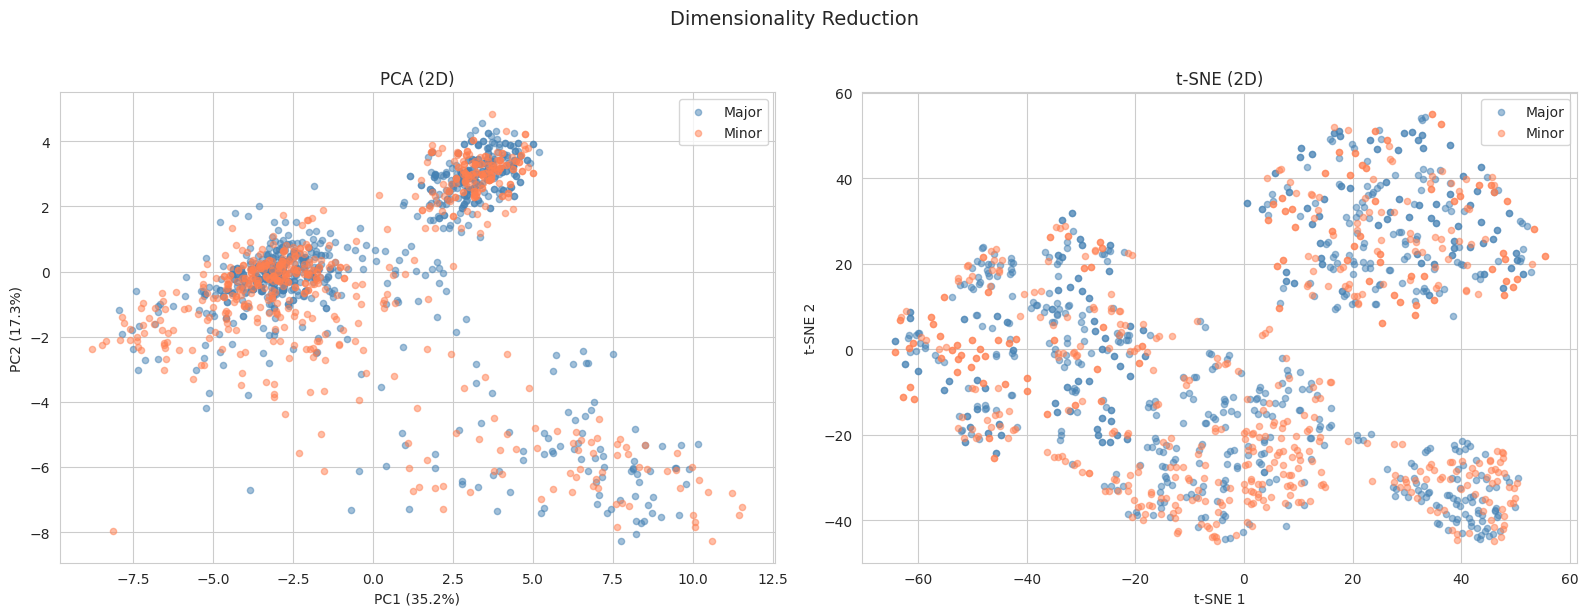

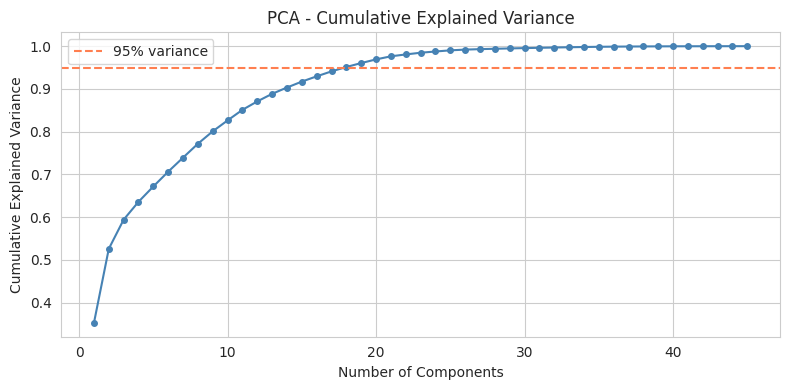

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
le = LabelEncoder()
y_encoded = le.fit_transform(labels)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for cls, color, name in [(0, 'steelblue', 'Major'), (1, 'coral', 'Minor')]:
    mask = y_encoded == cls
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=name, alpha=0.5, s=20)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PCA (2D)')
axes[0].legend()

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

for cls, color, name in [(0, 'steelblue', 'Major'), (1, 'coral', 'Minor')]:
    mask = y_encoded == cls
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=color, label=name, alpha=0.5, s=20)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].set_title('t-SNE (2D)')
axes[1].legend()

plt.suptitle('Dimensionality Reduction', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

pca_full = PCA().fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(cumvar) + 1), cumvar, marker='o', markersize=4, color='steelblue')
ax.axhline(y=0.95, color='coral', linestyle='--', label='95% variance')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('PCA - Cumulative Explained Variance')
ax.legend()
plt.tight_layout()
plt.show()

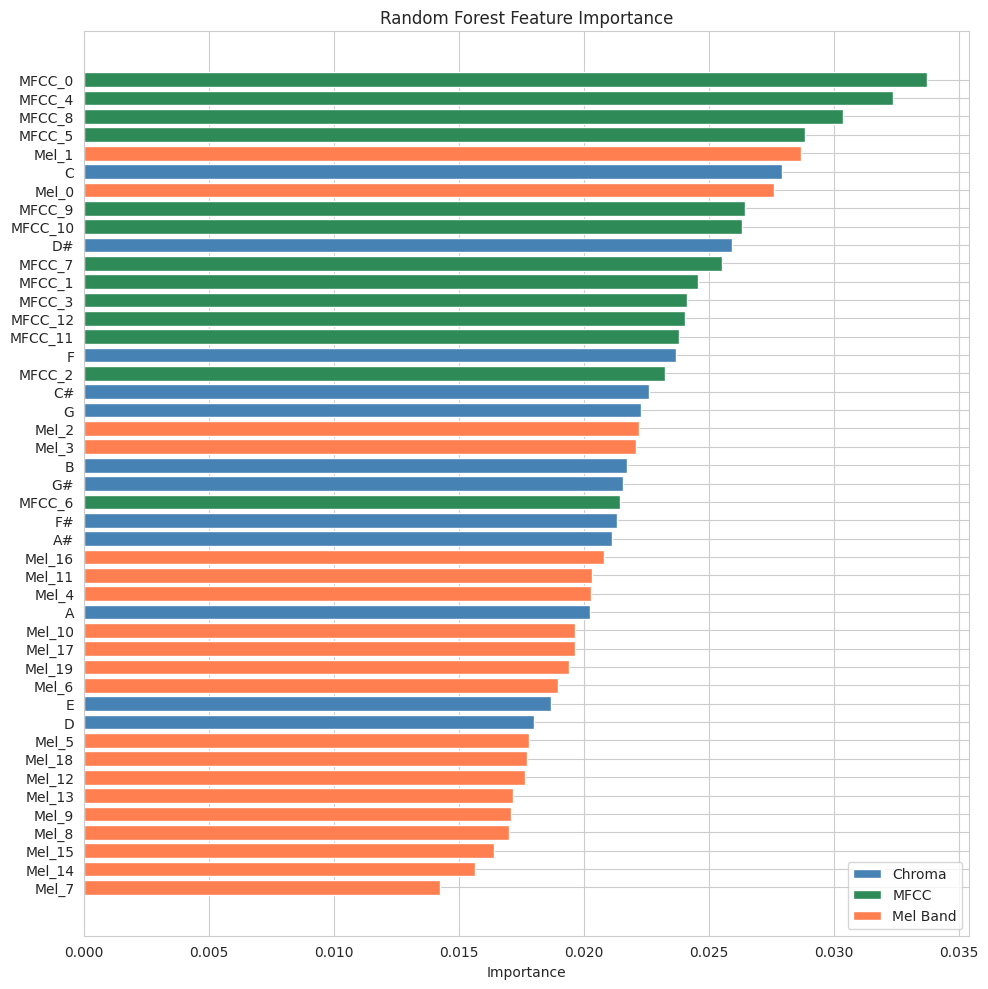

Top 10 most important features:
  MFCC_0: 0.0337
  MFCC_4: 0.0324
  MFCC_8: 0.0304
  MFCC_5: 0.0288
  Mel_1: 0.0287
  C: 0.0279
  Mel_0: 0.0276
  MFCC_9: 0.0264
  MFCC_10: 0.0263
  D#: 0.0259


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from matplotlib.patches import Patch

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, y_encoded)

importances = rf.feature_importances_
sorted_idx = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10, 10))
colors = []
for name in np.array(feature_names)[sorted_idx]:
    if name in chroma_names:
        colors.append('steelblue')
    elif name in mfcc_names:
        colors.append('seagreen')
    else:
        colors.append('coral')

ax.barh(np.array(feature_names)[sorted_idx], importances[sorted_idx], color=colors)
ax.set_xlabel('Importance')
ax.set_title('Random Forest Feature Importance')

legend_elements = [Patch(facecolor='steelblue', label='Chroma'),
                   Patch(facecolor='seagreen', label='MFCC'),
                   Patch(facecolor='coral', label='Mel Band')]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

top10_idx = sorted_idx[-10:]
print("Top 10 most important features:")
for i in reversed(top10_idx):
    print(f"  {feature_names[i]}: {importances[i]:.4f}")